# Ball Inference

In [1]:
# Manejo de datos y operaciones matemáticas
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid") # Configuración estética de Seaborn

# Procesamiento de imágenes/vídeo
import cv2

# Lectura de metadatos y archivos serializados
import json
import pickle
import os, sys # Útil para manejar las rutas 

# Para cargar datos
from kloppy import sportscode, metrica
sys.path.append('..')
import games

In [2]:
# Load ATD
sys.path.insert(0, os.path.abspath('..'))

print("Cargando Tracking ATD...")
paths = games.asset_paths(source='tactical')

dataset = metrica.load_tracking_epts(
    meta_data=paths['atd_meta'],
    raw_data=paths['atd_raw'], 
)

print(f"-> {len(dataset.records)} frames cargados con éxito.")
frame_df = dataset.to_df()
display(frame_df.head())

Cargando Tracking ATD...
-> 199319 frames cargados con éxito.


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
0,1,0 days 00:00:00.040000,1,None,None,NaN,NaN,None,None,0.33411,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
1,1,0 days 00:00:00.080000,2,None,None,NaN,NaN,None,None,0.33404,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
2,1,0 days 00:00:00.120000,3,None,None,NaN,NaN,None,None,0.33396,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
3,1,0 days 00:00:00.160000,4,None,None,NaN,NaN,None,None,0.33389,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4,1,0 days 00:00:00.200000,5,None,None,NaN,NaN,None,None,0.33382,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN


In [3]:
import pandas as pd
import numpy as np

# Rangos de frames de las mitades que me pasaste
HALVES_RANGES = {
    1: (1713242, 1792708),
    2: (1812866, 1892255)
}

HALVES_OFFSETS = {
    1: 1702057,
    2: 1702058
}

def clean_and_split_data(df_raw, halves_dict=HALVES_RANGES, max_players=46):
    """
    1. Filtra los frames para conservar únicamente los de las mitades especificadas.
    2. Selecciona solo las columnas necesarias (identificadores, balón y jugadores).
    3. Rellena nulos de jugadores inactivos (-1 en posición, 0 en velocidad).
    4. Genera el historial del balón de forma secuencial respetando los periodos.
    5. Divide el dataset en df_train (ball_x/y no nulos) y df_inference (ball_x/y son NaN).
    """
    # 1. Filtrar filas que estén dentro de los rangos de las mitades
    mask_halves = pd.Series(False, index=df_raw.index)
    for half_id, (start_f, end_f) in halves_dict.items():
        # Asumiendo que tu columna de frame se llama 'frame_id'
        mask_halves = mask_halves | ((df_raw['frame_id'] >= start_f-HALVES_OFFSETS[half_id]) & (df_raw['frame_id'] <= end_f-HALVES_OFFSETS[half_id]))
        
    df = df_raw[mask_halves].copy()
    
    # 2. Seleccionar columnas de interés
    base_cols = ['period_id', 'timestamp', 'frame_id', 'ball_x', 'ball_y']
    
    player_cols = []
    for i in range(1, max_players + 1):
        for suffix in ['x', 'y', 'd', 's']:
            col = f"{i}_{suffix}"
            if col in df.columns:
                player_cols.append(col)
                
    keep_cols = [c for c in base_cols if c in df.columns] + player_cols
    df = df[keep_cols].copy()
    
    # 3. Orden cronológico estricto
    df = df.sort_values(['period_id', 'frame_id']).reset_index(drop=True)
    
    # 4. Limpiar nulos de jugadores (suplentes fuera de campo)
    for col in player_cols:
        if col.endswith('_x') or col.endswith('_y'):
            df[col] = df[col].fillna(-1.0)
        else:
            df[col] = df[col].fillna(0.0)
            
    # 5. Generar el historial previo del balón de forma secuencial por periodo
    df['prev_ball_x'] = df.groupby('period_id')['ball_x'].shift(1).fillna(0.5)
    df['prev_ball_y'] = df.groupby('period_id')['ball_y'].shift(1).fillna(0.5)
    
    # 6. CREACIÓN DE LOS SUBSETS DE TRAINING E INFERENCIA
    # Train: Filas donde la pelota SÍ está presente
    df_train = df.dropna(subset=['ball_x', 'ball_y']).copy()
    
    # Inference: Filas donde la pelota es NaN y necesitamos predecirla
    df_inference = df[df['ball_x'].isna() | df['ball_y'].isna()].copy()
    
    return df_train, df_inference

# --- Ejemplo de uso en tu notebook del hakatron ---
df_train, df_inference = clean_and_split_data(frame_df)
print(f"Frames para entrenar: {len(df_train)}")
print(f"Frames para inferir (ball NaN): {len(df_inference)}")

C:\Users\Maria Fité\AppData\Local\Temp\ipykernel_13988\1857975675.py:52: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(0.0)
C:\Users\Maria Fité\AppData\Local\Temp\ipykernel_13988\1857975675.py:55: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['prev_ball_x'] = df.groupby('period_id')['ball_x'].shift(1).fillna(0.5)
C:\Users\Maria Fité\AppData\Local\Temp\ipykernel_13988\1857975675.py:56: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poo

Frames para entrenar: 94215
Frames para inferir (ball NaN): 64642


In [4]:
print(df_train.columns)

Index(['period_id', 'timestamp', 'frame_id', 'ball_x', 'ball_y', '1_x', '1_y',
       '1_d', '1_s', '2_x',
       ...
       '45_x', '45_y', '45_d', '45_s', '46_x', '46_y', '46_d', '46_s',
       'prev_ball_x', 'prev_ball_y'],
      dtype='object', length=191)


In [5]:
def check_missing_values(df):
    """
    Calcula la cantidad y el porcentaje de valores NaN por columna.
    """
    # Contar nulos por columna
    missing_count = df.isnull().sum()
    
    # Calcular el porcentaje respecto al total de filas
    missing_percentage = (missing_count / len(df)) * 100
    
    # Unir ambos resultados en un DataFrame ordenado de mayor a menor nulos
    df_missing = pd.DataFrame({
        'Nulos': missing_count,
        'Porcentaje (%)': missing_percentage
    })
    
    # Filtrar solo las columnas que tienen al menos un NaN y ordenar
    df_missing = df_missing[df_missing['Nulos'] > 0].sort_values(by='Nulos', ascending=False)
    
    return df_missing

# --- Uso en tu DataFrame ---
# Puedes pasárselo al DataFrame original antes de limpiar, o a df_inference
df_nan_report = check_missing_values(df_train)

print(f"Total de columnas con algún NaN: {len(df_nan_report)}")
display(df_nan_report.head(20)) # Muestra las 20 columnas con más nulos

Total de columnas con algún NaN: 0


,Nulos,Porcentaje (%)


In [6]:
import numpy as np
import pandas as pd

def create_chunked_train_test_split(df_train, chunk_size=10, num_test_chunks=1280, random_state=42):
    """
    Extrae bloques (chunks) aleatorios de 10 frames exclusivamente para el test, 
    y deja todo el resto del dataset original para el entrenamiento.
    
    Parameters:
    - df_train: DataFrame limpio con los datos de entrenamiento.
    - chunk_size: Número de frames consecutivos por cada bloque (por defecto 10).
    - num_test_chunks: Cantidad de bloques aleatorios que se reservarán para test.
    - random_state: Semilla para la reproducibilidad.
    """
    np.random.seed(random_state)
    max_idx = len(df_train) - chunk_size
    
    if max_idx <= 0:
        raise ValueError("El dataset es más pequeño que el tamaño del chunk especificado.")
        
    # Máscara booleana para llevar el control de qué filas van a train (True) y cuáles a test (False)
    mask = np.ones(len(df_train), dtype=bool)
    test_start_indices = []
    
    # Seleccionar bloques de test al azar intentando que no se solapen
    attempts = 0
    max_attempts = num_test_chunks * 10
    
    while len(test_start_indices) < num_test_chunks and attempts < max_attempts:
        start = np.random.randint(0, max_idx)
        end = start + chunk_size
        
        # Comprobar si el bloque completo está disponible en la máscara
        if np.all(mask[start:end]):
            test_start_indices.append(start)
            mask[start:end] = False  # Marcar estos índices como ocupados para el test
            
        attempts += 1
        
    # Extraer los DataFrames de test y de train usando la máscara
    test_chunks = [df_train.iloc[start : start + chunk_size] for start in test_start_indices]
    
    df_test_sub = pd.concat(test_chunks).reset_index(drop=True)
    df_train_sub = df_train[mask].reset_index(drop=True) # Todo lo que sobra va a train
    
    return df_train_sub, df_test_sub

# --- Ejemplo de uso ---
# Reserva 200 bloques de 10 frames (2.000 frames de test) y deja el resto para entrenar
df_train_sub, df_test_sub = create_chunked_train_test_split(
    df_train, 
    chunk_size=50, 
    num_test_chunks=256, 
    random_state=42
)

print(f"Frames totales en Train: {len(df_train_sub)}")
print(f"Frames totales en Test: {len(df_test_sub)} ({256} bloques de 50)")

Frames totales en Train: 81415
Frames totales en Test: 12800 (256 bloques de 50)


## GRU

In [7]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np

ASPECT_RATIO = 105.3 / 68.0

class FootballSeqDatasetRobust(Dataset):
    """
    Dataset robusto que respeta los saltos entre chunks discontinuos 
    y procesa los 46 jugadores reales del DataFrame.
    """
    def __init__(self, df_subset, seq_len=5, max_players=22, total_available_players=46):
        self.seq_len = seq_len
        self.max_players = max_players
        self.total_players = total_available_players
        self.samples = []
        
        if df_subset is None or len(df_subset) == 0:
            return
            
        # Ordenar cronológicamente
        df_sorted = df_subset.sort_values(['period_id', 'frame_id']).reset_index(drop=True)
        
        # Detectar saltos discontinuos (cuando cambian de periodo o hay huecos en frame_id > 1)
        df_sorted['is_break'] = (
            (df_sorted['period_id'] != df_sorted['period_id'].shift(1)) | 
            (df_sorted['frame_id'] != df_sorted['frame_id'].shift(1) + 1)
        )
        df_sorted['segment_id'] = df_sorted['is_break'].cumsum()
        
        # Procesar cada segmento continuo de forma independiente
        for seg_id, group in df_sorted.groupby('segment_id'):
            if len(group) <= seq_len:
                continue
                
            rows_data = []
            for _, row in group.iterrows():
                prev_bx = row.get('prev_ball_x', 0.5)
                prev_by = row.get('prev_ball_y', 0.5)
                
                players_list = []
                for i in range(1, self.total_players + 1):
                    px = row.get(f'{i}_x', -1.0)
                    py = row.get(f'{i}_y', -1.0)
                    if px < 0 or py < 0 or np.isnan(px) or np.isnan(py):
                        continue
                    ps = row.get(f'{i}_s', 0.0)
                    dx = (px - prev_bx) * ASPECT_RATIO
                    dy = (py - prev_by)
                    dist = np.sqrt(dx**2 + dy**2)
                    players_list.append({'x': px, 'y': py, 'speed': ps, 'dist': dist})
                
                # Ordenar del más cercano al más lejano y recortar a max_players
                players_list = sorted(players_list, key=lambda p: p['dist'])[:self.max_players]
                
                frame_feats = []
                for p in players_list:
                    frame_feats.extend([p['x'], p['y'], p['speed'], p['dist']])
                
                while len(frame_feats) < self.max_players * 4:
                    frame_feats.extend([0.0, 0.0, 0.0, 999.0])
                    
                frame_feats.extend([prev_bx, prev_by])
                rows_data.append({
                    'features': np.array(frame_feats, dtype=np.float32),
                    'ball_x': row['ball_x'],
                    'ball_y': row['ball_y']
                })
            
            # Generar ventanas deslizantes dentro del segmento
            for i in range(len(rows_data) - seq_len):
                window = rows_data[i : i + seq_len]
                target_row = rows_data[i + seq_len]
                
                seq_x = np.array([w['features'] for w in window], dtype=np.float32)
                target_y = np.array([target_row['ball_x'], target_row['ball_y']], dtype=np.float32)
                
                if not np.isnan(target_y).any():
                    self.samples.append((seq_x, target_y))
                    
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return torch.tensor(x), torch.tensor(y)


# ==========================================
# 1. ARQUITECTURA DE LA GRU
# ==========================================
class BallPredictorGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=2):
        super(BallPredictorGRU, self).__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2 if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )
        
    def forward(self, x):
        out, _ = self.gru(x)
        out = out[:, -1, :]
        preds = self.fc(out)
        return preds


# ==========================================
# 2. CONFIGURACIÓN Y DATALOADERS
# ==========================================
SEQ_LEN = 25          # Reducido a 5 para encajar perfectamente con chunks de 10
BATCH_SIZE = 128

train_dataset = FootballSeqDatasetRobust(df_train_sub, seq_len=SEQ_LEN)
test_dataset = FootballSeqDatasetRobust(df_test_sub, seq_len=SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Secuencias de entrenamiento preparadas: {len(train_dataset)}")
print(f"Secuencias de test preparadas: {len(test_dataset)}")


# ==========================================
# 3. ENTRENAMIENTO
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# input_dim = 22 jugadores * 4 features + 2 (prev_ball) = 90
input_dim = (22 * 4) + 2 

model = BallPredictorGRU(input_dim=input_dim).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 15
print(f"\nEntrenando GRU en dispositivo: {device}...")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    avg_loss = total_loss / len(train_loader) if len(train_loader) > 0 else 0
    print(f"Época {epoch+1}/{EPOCHS} - Loss (MSE): {avg_loss:.6f}")


# ==========================================
# 4. EVALUACIÓN EN METROS SOBRE EL TEST
# ==========================================
model.eval()
all_distances = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        preds = model(batch_x)
        
        # Convertir a numpy en CPU
        preds_np = preds.cpu().numpy()
        real_np = batch_y.cpu().numpy()
        
        # Calcular error en metros reales (105m x 68m)
        err_x = (preds_np[:, 0] - real_np[:, 0]) * 105.0
        err_y = (preds_np[:, 1] - real_np[:, 1]) * 68.0
        dist = np.sqrt(err_x**2 + err_y**2)
        
        all_distances.extend(dist)

all_distances = np.array(all_distances)

print("\n" + "="*30)
print("   RESULTADOS DE LA GRU (TEST)")
print("="*30)
print(f"Error Medio:    {np.mean(all_distances):.2f} metros")
print(f"Error Mediano:  {np.median(all_distances):.2f} metros")
print(f"Percentil 90:   {np.percentile(all_distances, 90):.2f} metros")
print("="*30)

Secuencias de entrenamiento preparadas: 72378
Secuencias de test preparadas: 6182

Entrenando GRU en dispositivo: cpu...
Época 1/15 - Loss (MSE): 0.025853
Época 2/15 - Loss (MSE): 0.012363
Época 3/15 - Loss (MSE): 0.010510
Época 4/15 - Loss (MSE): 0.009164
Época 5/15 - Loss (MSE): 0.008609
Época 6/15 - Loss (MSE): 0.008102
Época 7/15 - Loss (MSE): 0.007982
Época 8/15 - Loss (MSE): 0.007801
Época 9/15 - Loss (MSE): 0.007646
Época 10/15 - Loss (MSE): 0.007575
Época 11/15 - Loss (MSE): 0.007482
Época 12/15 - Loss (MSE): 0.007398
Época 13/15 - Loss (MSE): 0.007326
Época 14/15 - Loss (MSE): 0.007195
Época 15/15 - Loss (MSE): 0.007107

   RESULTADOS DE LA GRU (TEST)
Error Medio:    7.31 metros
Error Mediano:  2.84 metros
Percentil 90:   16.44 metros


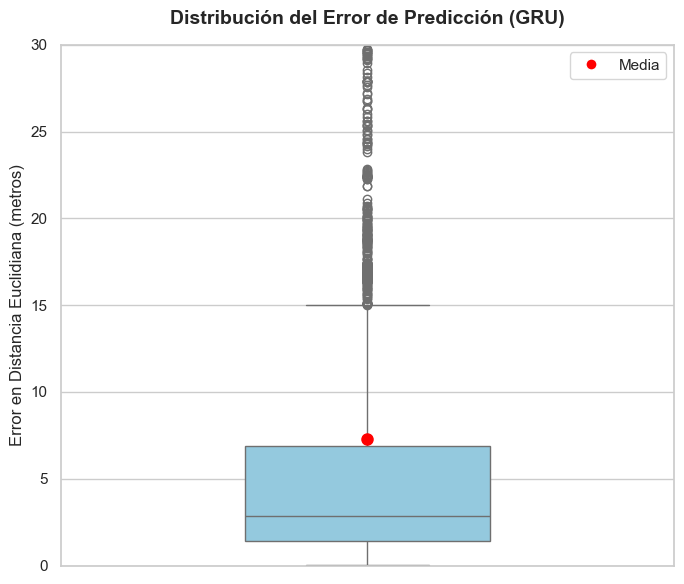

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética del gráfico
plt.figure(figsize=(7, 6))
sns.set_theme(style="whitegrid")

# Crear el boxplot
sns.boxplot(
    y=all_distances, 
    color="skyblue", 
    width=0.4,
    showmeans=True,  # Mostrar la media
    meanprops={
        "marker": "o", 
        "markerfacecolor": "red", 
        "markeredgecolor": "red", 
        "markersize": 8
    }
)

# Añadir etiquetas y formato
plt.title("Distribución del Error de Predicción (GRU)", fontsize=14, weight="bold", pad=15)
plt.ylabel("Error en Distancia Euclidiana (metros)", fontsize=12)
plt.ylim(0,30)

# Leyenda manual para el punto de la media
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', label='Media', markerfacecolor='red', markersize=8)], 
           loc='upper right')

plt.tight_layout()
plt.show()

## LSTM

In [9]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np

ASPECT_RATIO = 105.3 / 68.0

class FootballSeqDatasetRobust(Dataset):
    """
    Dataset robusto que respeta los saltos entre chunks discontinuos 
    y procesa los 46 jugadores reales del DataFrame.
    """
    def __init__(self, df_subset, seq_len=5, max_players=22, total_available_players=46):
        self.seq_len = seq_len
        self.max_players = max_players
        self.total_players = total_available_players
        self.samples = []
        
        if df_subset is None or len(df_subset) == 0:
            return
            
        # Ordenar cronológicamente
        df_sorted = df_subset.sort_values(['period_id', 'frame_id']).reset_index(drop=True)
        
        # Detectar saltos discontinuos
        df_sorted['is_break'] = (
            (df_sorted['period_id'] != df_sorted['period_id'].shift(1)) | 
            (df_sorted['frame_id'] != df_sorted['frame_id'].shift(1) + 1)
        )
        df_sorted['segment_id'] = df_sorted['is_break'].cumsum()
        
        # Procesar cada segmento continuo de forma independiente
        for seg_id, group in df_sorted.groupby('segment_id'):
            if len(group) <= seq_len:
                continue
                
            rows_data = []
            for _, row in group.iterrows():
                prev_bx = row.get('prev_ball_x', 0.5)
                prev_by = row.get('prev_ball_y', 0.5)
                
                players_list = []
                for i in range(1, self.total_players + 1):
                    px = row.get(f'{i}_x', -1.0)
                    py = row.get(f'{i}_y', -1.0)
                    if px < 0 or py < 0 or np.isnan(px) or np.isnan(py):
                        continue
                    ps = row.get(f'{i}_s', 0.0)
                    dx = (px - prev_bx) * ASPECT_RATIO
                    dy = (py - prev_by)
                    dist = np.sqrt(dx**2 + dy**2)
                    players_list.append({'x': px, 'y': py, 'speed': ps, 'dist': dist})
                
                # Ordenar del más cercano al más lejano y recortar a max_players
                players_list = sorted(players_list, key=lambda p: p['dist'])[:self.max_players]
                
                frame_feats = []
                for p in players_list:
                    frame_feats.extend([p['x'], p['y'], p['speed'], p['dist']])
                
                while len(frame_feats) < self.max_players * 4:
                    frame_feats.extend([0.0, 0.0, 0.0, 999.0])
                    
                frame_feats.extend([prev_bx, prev_by])
                rows_data.append({
                    'features': np.array(frame_feats, dtype=np.float32),
                    'ball_x': row['ball_x'],
                    'ball_y': row['ball_y']
                })
            
            # Generar ventanas deslizantes dentro del segmento
            for i in range(len(rows_data) - seq_len):
                window = rows_data[i : i + seq_len]
                target_row = rows_data[i + seq_len]
                
                seq_x = np.array([w['features'] for w in window], dtype=np.float32)
                target_y = np.array([target_row['ball_x'], target_row['ball_y']], dtype=np.float32)
                
                if not np.isnan(target_y).any():
                    self.samples.append((seq_x, target_y))
                    
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return torch.tensor(x), torch.tensor(y)


# ==========================================
# 1. ARQUITECTURA DE LA LSTM
# ==========================================
class BallPredictorLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=2):
        super(BallPredictorLSTM, self).__init__()
        # Cambiamos nn.GRU por nn.LSTM
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2 if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 2) # Predice directamente (X, Y)
        )
        
    def forward(self, x):
        # En LSTM, la salida devuelve una tupla: (output, (h_n, c_n))
        out, (h_n, c_n) = self.lstm(x)
        # Nos quedamos con la salida del último paso temporal
        out = out[:, -1, :]
        preds = self.fc(out)
        return preds


# ==========================================
# 2. CONFIGURACIÓN Y DATALOADERS
# ==========================================
SEQ_LEN = 25
BATCH_SIZE = 128

train_dataset = FootballSeqDatasetRobust(df_train_sub, seq_len=SEQ_LEN)
test_dataset = FootballSeqDatasetRobust(df_test_sub, seq_len=SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Secuencias de entrenamiento preparadas: {len(train_dataset)}")
print(f"Secuencias de test preparadas: {len(test_dataset)}")


# ==========================================
# 3. ENTRENAMIENTO
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = (22 * 4) + 2  # 90 dimensiones

model = BallPredictorLSTM(input_dim=input_dim, hidden_dim=128, num_layers=2).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 15
print(f"\nEntrenando LSTM en dispositivo: {device}...")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    avg_loss = total_loss / len(train_loader) if len(train_loader) > 0 else 0
    print(f"Época {epoch+1}/{EPOCHS} - Loss (MSE): {avg_loss:.6f}")


# ==========================================
# 4. EVALUACIÓN EN METROS SOBRE EL TEST
# ==========================================
model.eval()
all_distances = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        preds = model(batch_x)
        
        preds_np = preds.cpu().numpy()
        real_np = batch_y.cpu().numpy()
        
        err_x = (preds_np[:, 0] - real_np[:, 0]) * 105.3
        err_y = (preds_np[:, 1] - real_np[:, 1]) * 68.0
        dist = np.sqrt(err_x**2 + err_y**2)
        
        all_distances.extend(dist)

all_distances = np.array(all_distances)

print("\n" + "="*30)
print("   RESULTADOS DE LA LSTM (TEST)")
print("="*30)
if len(all_distances) > 0:
    print(f"Error Medio:    {np.mean(all_distances):.2f} metros")
    print(f"Error Mediano:  {np.median(all_distances):.2f} metros")
    print(f"Percentil 90:   {np.percentile(all_distances, 90):.2f} metros")
else:
    print("No se generaron muestras de test válidas.")
print("="*30)

Secuencias de entrenamiento preparadas: 72378
Secuencias de test preparadas: 6182

Entrenando LSTM en dispositivo: cpu...
Época 1/15 - Loss (MSE): 0.032811
Época 2/15 - Loss (MSE): 0.011532
Época 3/15 - Loss (MSE): 0.009933
Época 4/15 - Loss (MSE): 0.009097
Época 5/15 - Loss (MSE): 0.008749
Época 6/15 - Loss (MSE): 0.008496
Época 7/15 - Loss (MSE): 0.008242
Época 8/15 - Loss (MSE): 0.008062
Época 9/15 - Loss (MSE): 0.007921
Época 10/15 - Loss (MSE): 0.007821
Época 11/15 - Loss (MSE): 0.007676
Época 12/15 - Loss (MSE): 0.007660
Época 13/15 - Loss (MSE): 0.007450
Época 14/15 - Loss (MSE): 0.007412
Época 15/15 - Loss (MSE): 0.007295

   RESULTADOS DE LA LSTM (TEST)
Error Medio:    8.05 metros
Error Mediano:  3.64 metros
Percentil 90:   19.00 metros


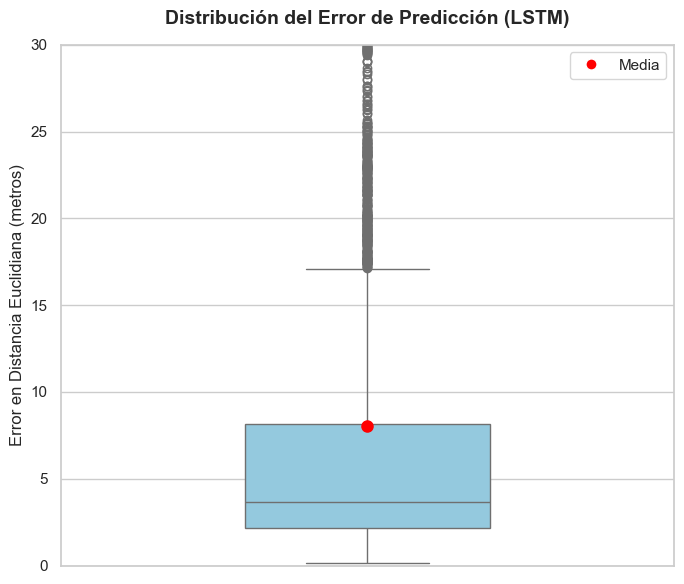

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética del gráfico
plt.figure(figsize=(7, 6))
sns.set_theme(style="whitegrid")

# Crear el boxplot
sns.boxplot(
    y=all_distances, 
    color="skyblue", 
    width=0.4,
    showmeans=True,  # Mostrar la media
    meanprops={
        "marker": "o", 
        "markerfacecolor": "red", 
        "markeredgecolor": "red", 
        "markersize": 8
    }
)

# Añadir etiquetas y formato
plt.title("Distribución del Error de Predicción (LSTM)", fontsize=14, weight="bold", pad=15)
plt.ylabel("Error en Distancia Euclidiana (metros)", fontsize=12)
plt.ylim(0,30)

# Leyenda manual para el punto de la media
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', label='Media', markerfacecolor='red', markersize=8)], 
           loc='upper right')

plt.tight_layout()
plt.show()

## Bi-GRU

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np

# Constantes del campo
ASPECT_RATIO = 105.3 / 68.0

# ==========================================
# 1. DATASET ROBUSTO (Ventana deslizante)
# ==========================================
class FootballSeqDatasetRobust(Dataset):
    """
    Dataset robusto que respeta los saltos entre chunks discontinuos 
    y procesa los 46 jugadores reales del DataFrame.
    """
    def __init__(self, df_subset, seq_len=25, max_players=22, total_available_players=46):
        self.seq_len = seq_len
        self.max_players = max_players
        self.total_players = total_available_players
        self.samples = []
        
        if df_subset is None or len(df_subset) == 0:
            return
            
        # Ordenar cronológicamente
        df_sorted = df_subset.sort_values(['period_id', 'frame_id']).reset_index(drop=True)
        
        # Detectar saltos discontinuos
        df_sorted['is_break'] = (
            (df_sorted['period_id'] != df_sorted['period_id'].shift(1)) | 
            (df_sorted['frame_id'] != df_sorted['frame_id'].shift(1) + 1)
        )
        df_sorted['segment_id'] = df_sorted['is_break'].cumsum()
        
        # Procesar cada segmento continuo de forma independiente
        for seg_id, group in df_sorted.groupby('segment_id'):
            if len(group) <= seq_len:
                continue
                
            rows_data = []
            for _, row in group.iterrows():
                prev_bx = row.get('prev_ball_x', 0.5)
                prev_by = row.get('prev_ball_y', 0.5)
                
                players_list = []
                for i in range(1, self.total_players + 1):
                    px = row.get(f'{i}_x', -1.0)
                    py = row.get(f'{i}_y', -1.0)
                    if px < 0 or py < 0 or np.isnan(px) or np.isnan(py):
                        continue
                    ps = row.get(f'{i}_s', 0.0)
                    dx = (px - prev_bx) * ASPECT_RATIO
                    dy = (py - prev_by)
                    dist = np.sqrt(dx**2 + dy**2)
                    players_list.append({'x': px, 'y': py, 'speed': ps, 'dist': dist})
                
                # Ordenar del más cercano al más lejano y recortar a max_players
                players_list = sorted(players_list, key=lambda p: p['dist'])[:self.max_players]
                
                frame_feats = []
                for p in players_list:
                    frame_feats.extend([p['x'], p['y'], p['speed'], p['dist']])
                
                while len(frame_feats) < self.max_players * 4:
                    frame_feats.extend([0.0, 0.0, 0.0, 999.0])
                    
                frame_feats.extend([prev_bx, prev_by])
                rows_data.append({
                    'features': np.array(frame_feats, dtype=np.float32),
                    'ball_x': row['ball_x'],
                    'ball_y': row['ball_y']
                })
            
            # Generar ventanas deslizantes dentro del segmento
            for i in range(len(rows_data) - seq_len):
                window = rows_data[i : i + seq_len]
                target_row = rows_data[i + seq_len]
                
                seq_x = np.array([w['features'] for w in window], dtype=np.float32)
                target_y = np.array([target_row['ball_x'], target_row['ball_y']], dtype=np.float32)
                
                if not np.isnan(target_y).any():
                    self.samples.append((seq_x, target_y))
                    
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return torch.tensor(x), torch.tensor(y)


# ==========================================
# 2. ARQUITECTURA DE LA BI-GRU
# ==========================================
class BiGRUPredictor(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=2):
        super(BiGRUPredictor, self).__init__()
        self.bigru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,  # <--- Bi-GRU (lee pasado y futuro inmediato)
            dropout=0.2 if num_layers > 1 else 0.0
        )
        # Al ser bidireccional, la dimensión oculta se duplica (hidden_dim * 2)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)  # Predice (X, Y)
        )
        
    def forward(self, x):
        out, _ = self.bigru(x)
        # Cogemos la última salida temporal de la secuencia
        out = out[:, -1, :]
        preds = self.fc(out)
        return preds


# ==========================================
# 3. CONFIGURACIÓN Y DATALOADERS
# ==========================================
SEQ_LEN = 25       # 1 segundo de contexto a 25 fps
BATCH_SIZE = 128

train_dataset = FootballSeqDatasetRobust(df_train_sub, seq_len=SEQ_LEN)
test_dataset = FootballSeqDatasetRobust(df_test_sub, seq_len=SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Secuencias de entrenamiento preparadas (Bi-GRU): {len(train_dataset)}")
print(f"Secuencias de test preparadas (Bi-GRU): {len(test_dataset)}")


# ==========================================
# 4. ENTRENAMIENTO
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = (22 * 4) + 2  # 90 dimensiones

model = BiGRUPredictor(input_dim=input_dim, hidden_dim=128, num_layers=2).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 15
print(f"\nEntrenando Bi-GRU en dispositivo: {device}...")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    avg_loss = total_loss / len(train_loader) if len(train_loader) > 0 else 0
    print(f"Época {epoch+1}/{EPOCHS} - Loss (MSE): {avg_loss:.6f}")


# ==========================================
# 5. EVALUACIÓN EN METROS SOBRE EL TEST
# ==========================================
model.eval()
all_distances = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        preds = model(batch_x)
        
        preds_np = preds.cpu().numpy()
        real_np = batch_y.cpu().numpy()
        
        err_x = (preds_np[:, 0] - real_np[:, 0]) * 105.3
        err_y = (preds_np[:, 1] - real_np[:, 1]) * 68.0
        dist = np.sqrt(err_x**2 + err_y**2)
        
        all_distances.extend(dist)

all_distances = np.array(all_distances)

print("\n" + "="*30)
print("   RESULTADOS DE LA BI-GRU (TEST)")
print("="*30)
if len(all_distances) > 0:
    print(f"Error Medio:    {np.mean(all_distances):.2f} metros")
    print(f"Error Mediano:  {np.median(all_distances):.2f} metros")
    print(f"Percentil 90:   {np.percentile(all_distances, 90):.2f} metros")
else:
    print("No se generaron muestras de test válidas.")
print("="*30)

Secuencias de entrenamiento preparadas (Bi-GRU): 72378
Secuencias de test preparadas (Bi-GRU): 6182

Entrenando Bi-GRU en dispositivo: cpu...
Época 1/15 - Loss (MSE): 0.034888
Época 2/15 - Loss (MSE): 0.022250
Época 3/15 - Loss (MSE): 0.020277
Época 4/15 - Loss (MSE): 0.016733
Época 5/15 - Loss (MSE): 0.012412
Época 6/15 - Loss (MSE): 0.011475
Época 7/15 - Loss (MSE): 0.011045
Época 8/15 - Loss (MSE): 0.010808
Época 9/15 - Loss (MSE): 0.010523
Época 10/15 - Loss (MSE): 0.010282
Época 11/15 - Loss (MSE): 0.010136
Época 12/15 - Loss (MSE): 0.010035
Época 13/15 - Loss (MSE): 0.009920
Época 14/15 - Loss (MSE): 0.008900
Época 15/15 - Loss (MSE): 0.008615

   RESULTADOS DE LA BI-GRU (TEST)
Error Medio:    8.12 metros
Error Mediano:  3.87 metros
Percentil 90:   18.84 metros


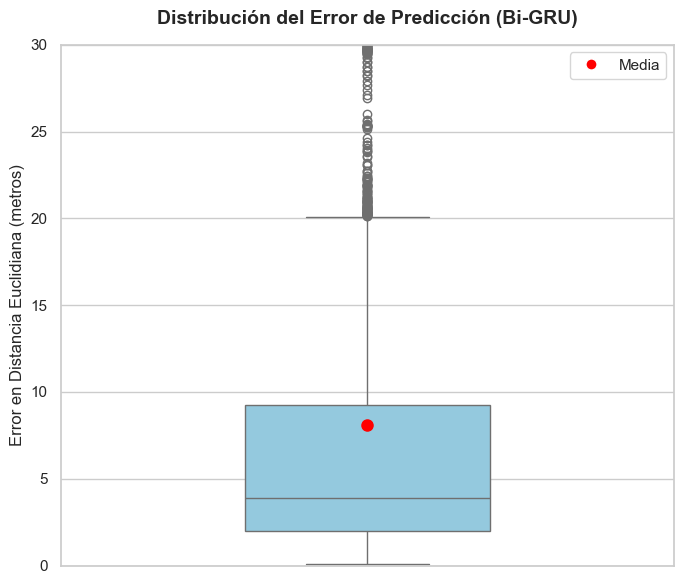

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética del gráfico
plt.figure(figsize=(7, 6))
sns.set_theme(style="whitegrid")

# Crear el boxplot
sns.boxplot(
    y=all_distances, 
    color="skyblue", 
    width=0.4,
    showmeans=True,  # Mostrar la media
    meanprops={
        "marker": "o", 
        "markerfacecolor": "red", 
        "markeredgecolor": "red", 
        "markersize": 8
    }
)

# Añadir etiquetas y formato
plt.title("Distribución del Error de Predicción (Bi-GRU)", fontsize=14, weight="bold", pad=15)
plt.ylabel("Error en Distancia Euclidiana (metros)", fontsize=12)
plt.ylim(0,30)

# Leyenda manual para el punto de la media
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', label='Media', markerfacecolor='red', markersize=8)], 
           loc='upper right')

plt.tight_layout()
plt.show()

## Bi-LSTM

In [13]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np

# Constantes del campo
ASPECT_RATIO = 105.3 / 68.0

# ==========================================
# 1. DATASET ROBUSTO (Ventana deslizante)
# ==========================================
class FootballSeqDatasetRobust(Dataset):
    """
    Dataset robusto que respeta los saltos entre chunks discontinuos 
    y procesa los 46 jugadores reales del DataFrame.
    """
    def __init__(self, df_subset, seq_len=25, max_players=22, total_available_players=46):
        self.seq_len = seq_len
        self.max_players = max_players
        self.total_players = total_available_players
        self.samples = []
        
        if df_subset is None or len(df_subset) == 0:
            return
            
        # Ordenar cronológicamente
        df_sorted = df_subset.sort_values(['period_id', 'frame_id']).reset_index(drop=True)
        
        # Detectar saltos discontinuos
        df_sorted['is_break'] = (
            (df_sorted['period_id'] != df_sorted['period_id'].shift(1)) | 
            (df_sorted['frame_id'] != df_sorted['frame_id'].shift(1) + 1)
        )
        df_sorted['segment_id'] = df_sorted['is_break'].cumsum()
        
        # Procesar cada segmento continuo de forma independiente
        for seg_id, group in df_sorted.groupby('segment_id'):
            if len(group) <= seq_len:
                continue
                
            rows_data = []
            for _, row in group.iterrows():
                prev_bx = row.get('prev_ball_x', 0.5)
                prev_by = row.get('prev_ball_y', 0.5)
                
                players_list = []
                for i in range(1, self.total_players + 1):
                    px = row.get(f'{i}_x', -1.0)
                    py = row.get(f'{i}_y', -1.0)
                    if px < 0 or py < 0 or np.isnan(px) or np.isnan(py):
                        continue
                    ps = row.get(f'{i}_s', 0.0)
                    dx = (px - prev_bx) * ASPECT_RATIO
                    dy = (py - prev_by)
                    dist = np.sqrt(dx**2 + dy**2)
                    players_list.append({'x': px, 'y': py, 'speed': ps, 'dist': dist})
                
                # Ordenar del más cercano al más lejano y recortar a max_players
                players_list = sorted(players_list, key=lambda p: p['dist'])[:self.max_players]
                
                frame_feats = []
                for p in players_list:
                    frame_feats.extend([p['x'], p['y'], p['speed'], p['dist']])
                
                while len(frame_feats) < self.max_players * 4:
                    frame_feats.extend([0.0, 0.0, 0.0, 999.0])
                    
                frame_feats.extend([prev_bx, prev_by])
                rows_data.append({
                    'features': np.array(frame_feats, dtype=np.float32),
                    'ball_x': row['ball_x'],
                    'ball_y': row['ball_y']
                })
            
            # Generar ventanas deslizantes dentro del segmento
            for i in range(len(rows_data) - seq_len):
                window = rows_data[i : i + seq_len]
                target_row = rows_data[i + seq_len]
                
                seq_x = np.array([w['features'] for w in window], dtype=np.float32)
                target_y = np.array([target_row['ball_x'], target_row['ball_y']], dtype=np.float32)
                
                if not np.isnan(target_y).any():
                    self.samples.append((seq_x, target_y))
                    
    def __len__(self):
        return len(self.samples)
        
    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return torch.tensor(x), torch.tensor(y)


# ==========================================
# 2. ARQUITECTURA DE LA BI-LSTM
# ==========================================
class BiLSTMPredictor(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=2):
        super(BiLSTMPredictor, self).__init__()
        self.bilstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,  # <--- Bi-LSTM (lee pasado y futuro inmediato)
            dropout=0.2 if num_layers > 1 else 0.0
        )
        # Al ser bidireccional, la dimensión oculta se duplica (hidden_dim * 2)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)  # Predice (X, Y)
        )
        
    def forward(self, x):
        out, (h_n, c_n) = self.bilstm(x)
        # Cogemos la última salida temporal de la secuencia
        out = out[:, -1, :]
        preds = self.fc(out)
        return preds


# ==========================================
# 3. CONFIGURACIÓN Y DATALOADERS
# ==========================================
SEQ_LEN = 25       # 1 segundo de contexto a 25 fps
BATCH_SIZE = 128

train_dataset = FootballSeqDatasetRobust(df_train_sub, seq_len=SEQ_LEN)
test_dataset = FootballSeqDatasetRobust(df_test_sub, seq_len=SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Secuencias de entrenamiento preparadas (Bi-LSTM): {len(train_dataset)}")
print(f"Secuencias de test preparadas (Bi-LSTM): {len(test_dataset)}")


# ==========================================
# 4. ENTRENAMIENTO
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = (22 * 4) + 2  # 90 dimensiones

model = BiLSTMPredictor(input_dim=input_dim, hidden_dim=128, num_layers=2).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 15
print(f"\nEntrenando Bi-LSTM en dispositivo: {device}...")

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    avg_loss = total_loss / len(train_loader) if len(train_loader) > 0 else 0
    print(f"Época {epoch+1}/{EPOCHS} - Loss (MSE): {avg_loss:.6f}")


# ==========================================
# 5. EVALUACIÓN EN METROS SOBRE EL TEST
# ==========================================
model.eval()
all_distances = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        preds = model(batch_x)
        
        preds_np = preds.cpu().numpy()
        real_np = batch_y.cpu().numpy()
        
        err_x = (preds_np[:, 0] - real_np[:, 0]) * 105.3
        err_y = (preds_np[:, 1] - real_np[:, 1]) * 68.0
        dist = np.sqrt(err_x**2 + err_y**2)
        
        all_distances.extend(dist)

all_distances = np.array(all_distances)

print("\n" + "="*30)
print("   RESULTADOS DE LA BI-LSTM (TEST)")
print("="*30)
if len(all_distances) > 0:
    print(f"Error Medio:    {np.mean(all_distances):.2f} metros")
    print(f"Error Mediano:  {np.median(all_distances):.2f} metros")
    print(f"Percentil 90:   {np.percentile(all_distances, 90):.2f} metros")
else:
    print("No se generaron muestras de test válidas.")
print("="*30)

Secuencias de entrenamiento preparadas (Bi-LSTM): 72378
Secuencias de test preparadas (Bi-LSTM): 6182

Entrenando Bi-LSTM en dispositivo: cpu...
Época 1/15 - Loss (MSE): 0.037384
Época 2/15 - Loss (MSE): 0.015582
Época 3/15 - Loss (MSE): 0.012795
Época 4/15 - Loss (MSE): 0.011380
Época 5/15 - Loss (MSE): 0.010581
Época 6/15 - Loss (MSE): 0.010131
Época 7/15 - Loss (MSE): 0.009784
Época 8/15 - Loss (MSE): 0.009431
Época 9/15 - Loss (MSE): 0.009114
Época 10/15 - Loss (MSE): 0.007165
Época 11/15 - Loss (MSE): 0.006498
Época 12/15 - Loss (MSE): 0.006313
Época 13/15 - Loss (MSE): 0.006156
Época 14/15 - Loss (MSE): 0.006001
Época 15/15 - Loss (MSE): 0.006117

   RESULTADOS DE LA BI-LSTM (TEST)
Error Medio:    8.20 metros
Error Mediano:  3.65 metros
Percentil 90:   19.32 metros


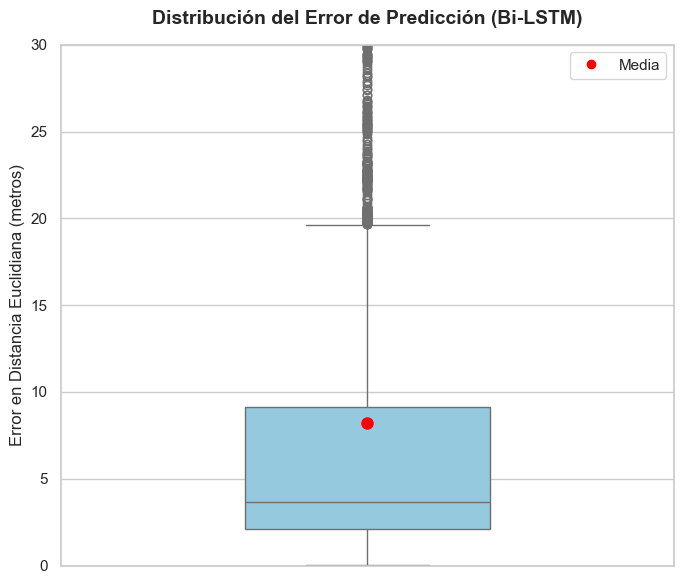

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética del gráfico
plt.figure(figsize=(7, 6))
sns.set_theme(style="whitegrid")

# Crear el boxplot
sns.boxplot(
    y=all_distances, 
    color="skyblue", 
    width=0.4,
    showmeans=True,  # Mostrar la media
    meanprops={
        "marker": "o", 
        "markerfacecolor": "red", 
        "markeredgecolor": "red", 
        "markersize": 8
    }
)

# Añadir etiquetas y formato
plt.title("Distribución del Error de Predicción (Bi-LSTM)", fontsize=14, weight="bold", pad=15)
plt.ylabel("Error en Distancia Euclidiana (metros)", fontsize=12)
plt.ylim(0,30)

# Leyenda manual para el punto de la media
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', label='Media', markerfacecolor='red', markersize=8)], 
           loc='upper right')

plt.tight_layout()
plt.show()